In [4]:
import warnings
warnings.filterwarnings('ignore')

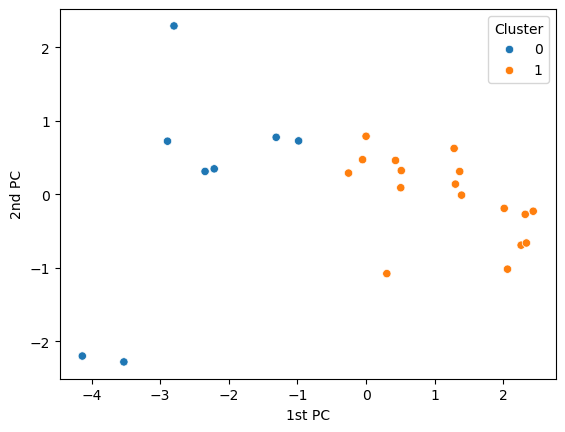

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
import os
os.chdir("D:\\Machine Learning\\Datasets")
milk = pd.read_csv("milk.csv", index_col=0)
scaler = StandardScaler().set_output(transform="pandas")
df_scaled = scaler.fit_transform(milk)
km = KMeans(n_clusters=4, random_state=25)
km.fit(df_scaled)
silhouette_score(df_scaled, labels=km.labels_)
clusters = [2, 3, 4, 5, 6, 7, 8]
scores = []
for k in clusters:
    km = KMeans(n_clusters=k, random_state=25)
    km.fit(df_scaled)
    score = silhouette_score(df_scaled, labels=km.labels_)
    scores.append([k, score])
df_scores = pd.DataFrame(scores, columns=["Clusters", "Score"])
df_scores.sort_values(by="Score", ascending=False)
pccomp = PCA().set_output(transform='pandas')
pcdata = pccomp.fit_transform(df_scaled)
clust = KMeans(n_clusters=2, random_state=25)
clust.fit(df_scaled)
pcdata = pcdata.iloc[:,:2]
pcdata['Cluster'] = clust.labels_
sns.scatterplot(data=pcdata, x='pca0', y='pca1', hue='Cluster')
plt.xlabel('1st PC')
plt.ylabel('2nd PC')
plt.show()


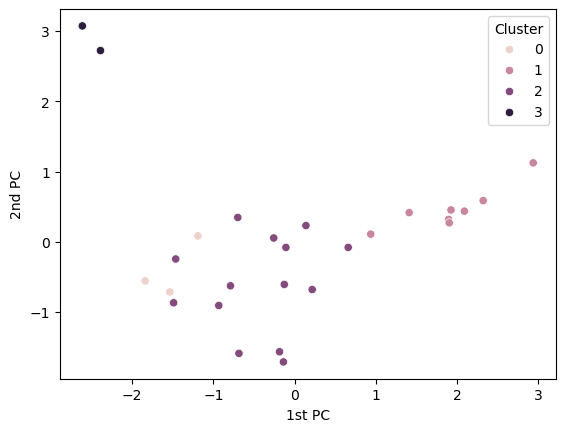

In [6]:
### Nutrients
nut = pd.read_csv("nutrient.csv", index_col=0)
scaler = StandardScaler().set_output(transform="pandas")
df_scaled = scaler.fit_transform(nut)
km = KMeans(n_clusters=4, random_state=25)
km.fit(df_scaled)
silhouette_score(df_scaled, labels=km.labels_)
clusters = [2, 3, 4, 5, 6, 7, 8]
scores = []
for k in clusters:
    km = KMeans(n_clusters=k, random_state=25)
    km.fit(df_scaled)
    score = silhouette_score(df_scaled, labels=km.labels_)
    scores.append([k, score])
df_scores = pd.DataFrame(scores, columns=["Clusters", "Score"])
df_scores.sort_values(by="Score", ascending=False)
pccomp = PCA().set_output(transform='pandas')
pcdata = pccomp.fit_transform(df_scaled)
clust = KMeans(n_clusters=4, random_state=25)
clust.fit(df_scaled)
pcdata = pcdata.iloc[:,:2]
pcdata['Cluster'] = clust.labels_
sns.scatterplot(data=pcdata, x='pca0', y='pca1', hue='Cluster')
plt.xlabel('1st PC')
plt.ylabel('2nd PC')
plt.show()

In [9]:
km=KMeans(n_clusters=2,random_state=25)
km.fit(df_scaled)
df_cluster=nut.copy()
df_cluster['cluster']=km.labels_
df_cluster.groupby('cluster').mean()


,energy,protein,fat,calcium,iron
cluster,,,,,
0,145.555556,19.0,6.444444,61.555556,2.338889
1,331.111111,19.0,27.555556,8.777778,2.466667
